<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/07_Feature_Importance_and_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Notebook 3 – Feature Importance & Model Explainability
### GeoAI for Future Earth | ACRS Training Workshop 2026

**Learning objectives:**
- Interpret RF predictions with **native (impurity-based) feature importance**
- Understand **permutation importance** as a model-agnostic alternative
- Apply **SHAP (SHapley Additive exPlanations)** to RF and XGBoost
- Visualise global and per-class feature contributions with SHAP plots


## 0 · Setup

In [1]:
%%capture
!pip install rioxarray geopandas xarray scikit-learn xgboost shap matplotlib seaborn


## 1 · Data Preparation & Model Training
*(Standalone – re-runs preprocessing and trains tuned RF + XGBoost)*

In [2]:
import os, subprocess, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# ── Clone repository ──────────────────────────────────────────
REPO_URL = 'https://github.com/nilaynishant/AIMLTutorial.git'
REPO_DIR = '/content/AIMLTutorial'
if not os.path.exists(REPO_DIR):
    subprocess.run(['git', 'clone', '--depth=1', REPO_URL, REPO_DIR],
                   capture_output=True, check=True)
    print("Repository cloned.")
else:
    print("Repository already present.")

RASTER_PATH = f'{REPO_DIR}/Data/Sentinel2_Agartala.tif'
POINTS_PATH = f'{REPO_DIR}/Data/Training.gpkg'

# ── Load raster and assign band names ────────────────────────
# Bands in the TIF: Band1=B8A(NIR), Band2=B4(Red), Band3=B3(Green), Band4=B2(Blue)
img = rxr.open_rasterio(RASTER_PATH).assign_coords(band=['B8A', 'B4', 'B3', 'B2'])
img_ref = img.astype(float) / 10000.0   # scale DN → surface reflectance

nir, red, green, blue = (img_ref.sel(band=b) for b in ['B8A', 'B4', 'B3', 'B2'])

# ── Spectral indices ──────────────────────────────────────────
ndvi = (nir - red)   / (nir + red)
ndwi = (green - nir) / (green + nir)
savi = 1.5 * (nir - red) / (nir + red + 0.5)
evi  = (2.5 * (nir - red) / (nir + 6*red - 7.5*blue + 1)).clip(-2, 2)

def _band(da, name):
    return da.expand_dims({'band': [name]})

stacked = xr.concat([
    img_ref,
    _band(ndvi, 'NDVI'), _band(ndwi, 'NDWI'),
    _band(savi, 'SAVI'), _band(evi,  'EVI')
], dim='band')

FEATURE_NAMES = stacked.band.values.tolist()
CLASS_MAP = {1: 'Vegetation', 2: 'Builtup', 3: 'Water', 4: 'Agriculture', 5: 'Fallow'}
LULC_COLORS = ['#2ECC71', '#E74C3C', '#3498DB', '#F1C40F', '#95A5A6']

# ── Sample pixel values at training points ────────────────────
gdf = gpd.read_file(POINTS_PATH).to_crs(stacked.rio.crs)
xs = xr.DataArray(gdf.geometry.x.values, dims=['pts'])
ys = xr.DataArray(gdf.geometry.y.values, dims=['pts'])
sampled = stacked.sel(x=xs, y=ys, method='nearest')  # (bands, n_pts)

df = pd.DataFrame(sampled.values.T, columns=FEATURE_NAMES)
df.insert(0, 'label',      gdf['id'].values)
df.insert(1, 'class_name', df['label'].map(CLASS_MAP))

print(f"Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print(f"Training samples: {len(df)}  |  Classes: {df['label'].nunique()}")
df.head()


Repository cloned.
Features (8): ['B8A', 'B4', 'B3', 'B2', 'NDVI', 'NDWI', 'SAVI', 'EVI']
Training samples: 51  |  Classes: 5


,label,class_name,B8A,B4,B3,B2,NDVI,NDWI,SAVI,EVI
0,1,Vegetation,0.2353,0.0430,0.0569,0.0446,0.690981,-0.610541,0.370615,0.414869
1,1,Vegetation,0.2664,0.0500,0.0601,0.0446,0.683944,-0.631853,0.397599,0.439159
2,1,Vegetation,0.2628,0.0451,0.0577,0.0433,0.707048,-0.639938,0.404196,0.450296
3,1,Vegetation,0.2335,0.0481,0.0613,0.0476,0.658381,-0.584125,0.355809,0.397820
4,1,Vegetation,0.2535,0.0679,0.0795,0.0607,0.577474,-0.522523,0.338934,0.384855


In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

X = df[FEATURE_NAMES].values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tuned RF
rf_gs = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': [100, 200], 'max_depth': [None, 10], 'max_features': ['sqrt', 'log2']},
    cv=cv, scoring='accuracy', n_jobs=-1)
rf_gs.fit(X_train, y_train)
best_rf = rf_gs.best_estimator_

# Tuned XGBoost
xgb_gs = GridSearchCV(
    XGBClassifier(use_label_encoder=False, eval_metric='mlogloss',
                  random_state=42, verbosity=0),
    {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.1, 0.3]},
    cv=cv, scoring='accuracy', n_jobs=-1)
xgb_gs.fit(X_train, y_train - 1)
best_xgb = xgb_gs.best_estimator_

print(f"RF  best CV acc  : {rf_gs.best_score_*100:.1f}%  | {rf_gs.best_params_}")
print(f"XGB best CV acc : {xgb_gs.best_score_*100:.1f}%  | {xgb_gs.best_params_}")


RF  best CV acc  : 85.7%  | {'max_depth': None, 'max_features': 'log2', 'n_estimators': 200}
XGB best CV acc : 82.9%  | {'learning_rate': 0.3, 'max_depth': 3, 'n_estimators': 200}


## 2 · RF Native Feature Importance (Impurity / Gini)

Random Forest accumulates the **mean decrease in Gini impurity** across all trees for each
feature. While fast to compute, this method can overestimate continuous or high-cardinality
features. Always cross-check with permutation or SHAP importance.


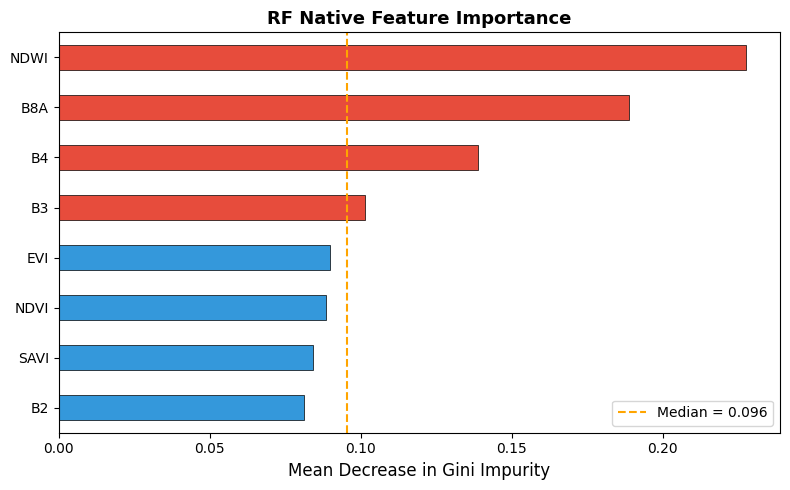


Feature importances (sorted):
NDWI    0.227381
B8A     0.188742
B4      0.138948
B3      0.101370
EVI     0.089803
NDVI    0.088461
SAVI    0.084036
B2      0.081258


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Extract and sort importances
rf_importances = pd.Series(best_rf.feature_importances_, index=FEATURE_NAMES)
rf_importances = rf_importances.sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors_bars = ['#E74C3C' if v > rf_importances.median() else '#3498DB'
               for v in rf_importances]
rf_importances.plot(kind='barh', ax=ax, color=colors_bars, edgecolor='black', linewidth=0.5)
ax.axvline(rf_importances.median(), color='orange', linestyle='--', linewidth=1.5,
           label=f'Median = {rf_importances.median():.3f}')
ax.set_xlabel('Mean Decrease in Gini Impurity', fontsize=12)
ax.set_title('RF Native Feature Importance', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print("\nFeature importances (sorted):")
print(rf_importances.sort_values(ascending=False).to_string())


## 3 · Permutation Feature Importance

Permutation importance measures how much the model's **accuracy drops** when a single
feature's values are randomly shuffled (breaking its relationship with the target).
This is more reliable than impurity-based importance and works for **any** model.


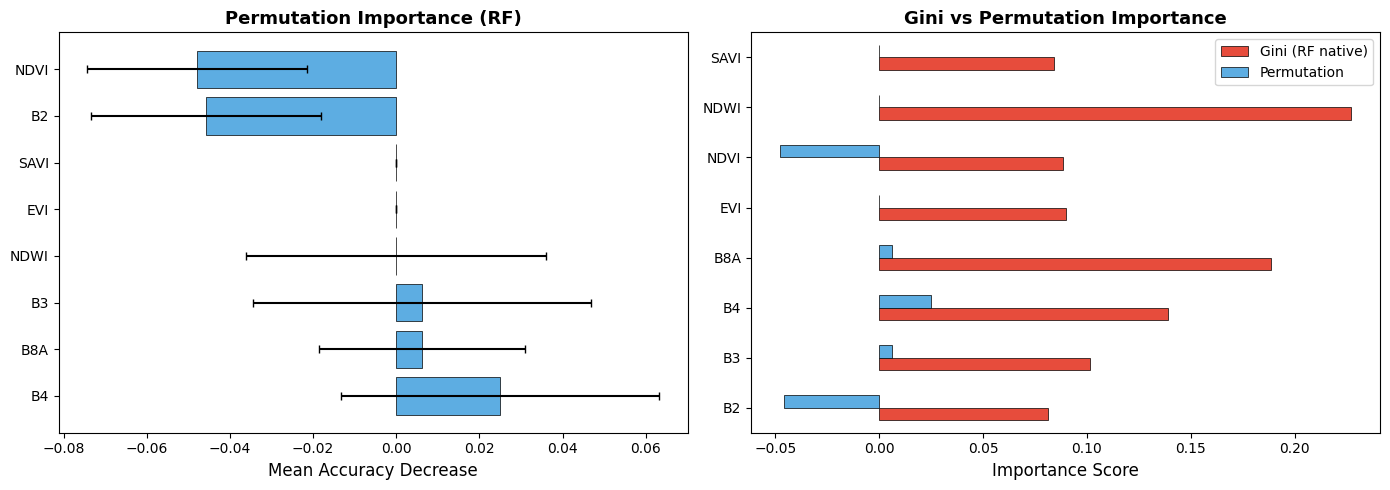

In [5]:
from sklearn.inspection import permutation_importance

# Compute for RF on test set (n_repeats=30 for stable estimates)
perm_rf = permutation_importance(best_rf, X_test, y_test,
                                  n_repeats=30, random_state=42, n_jobs=-1)

perm_df = pd.DataFrame({
    'feature'  : FEATURE_NAMES,
    'mean'     : perm_rf.importances_mean,
    'std'      : perm_rf.importances_std
}).sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Permutation importance bar + error bars
axes[0].barh(perm_df['feature'], perm_df['mean'],
             xerr=perm_df['std'], color='#5DADE2',
             edgecolor='black', linewidth=0.5, capsize=3)
axes[0].set_xlabel('Mean Accuracy Decrease', fontsize=12)
axes[0].set_title('Permutation Importance (RF)', fontsize=13, fontweight='bold')

# Compare Gini vs Permutation
compare = pd.DataFrame({
    'Gini (RF native)': rf_importances,
    'Permutation'     : perm_df.set_index('feature')['mean']
}).fillna(0)
compare.plot(kind='barh', ax=axes[1], color=['#E74C3C', '#5DADE2'],
             edgecolor='black', linewidth=0.5)
axes[1].set_xlabel('Importance Score', fontsize=12)
axes[1].set_title('Gini vs Permutation Importance', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


## 4 · SHAP Explanations

**SHAP (SHapley Additive exPlanations)** uses game-theoretic Shapley values to fairly
distribute each prediction's outcome among all features.

Key SHAP plots:
| Plot | What it shows |
|------|--------------|
| `summary_plot` | Global feature importance + direction of effect |
| `beeswarm`     | Each sample's SHAP value, coloured by feature value |
| `bar`          | Mean absolute SHAP per feature |
| `dependence_plot` | SHAP value vs feature value for one feature |


In [6]:
import shap
shap.initjs()

# SHAP TreeExplainer is optimised for tree-based models
explainer_rf = shap.TreeExplainer(best_rf)

# For multiclass RF, shap_values is a list: one (n_samples, n_features) array per class
shap_values_rf = explainer_rf.shap_values(X_test)

print(f"SHAP values type  : {type(shap_values_rf)}")
print(f"Number of classes : {len(shap_values_rf)}")
print(f"Shape per class   : {shap_values_rf[0].shape}")


SHAP values type  : <class 'numpy.ndarray'>
Number of classes : 16
Shape per class   : (8, 5)


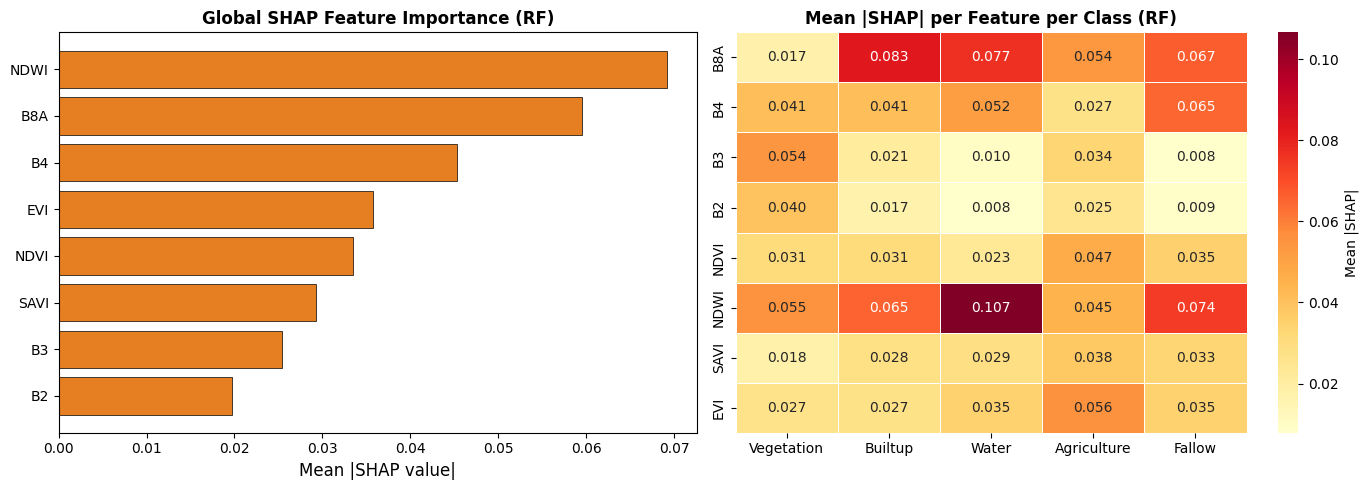

In [14]:
# ── Global SHAP summary (mean |SHAP| across all classes) ───────
# In newer SHAP versions, shap_values_rf shape is (n_samples, n_features, n_classes) = (16, 8, 5)
# Let's align its shape to (n_classes, n_samples, n_features) i.e. (5, 16, 8)
if shap_values_rf.shape == (16, 8, 5):
    shap_values_rf_aligned = np.transpose(shap_values_rf, (2, 0, 1))
else:
    shap_values_rf_aligned = shap_values_rf

shap_mean = np.mean(np.abs(shap_values_rf_aligned), axis=0) # shape (16, 8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart – mean |SHAP|
mean_shap_per_feat = shap_mean.mean(axis=0) # shape (8,)
order = np.argsort(mean_shap_per_feat)
axes[0].barh([FEATURE_NAMES[i] for i in order], mean_shap_per_feat[order],
             color='#E67E22', edgecolor='black', linewidth=0.5)
axes[0].set_xlabel('Mean |SHAP value|', fontsize=12)
axes[0].set_title('Global SHAP Feature Importance (RF)', fontsize=12, fontweight='bold')

# Per-class heatmap
shap_per_class = pd.DataFrame(
    {CLASS_MAP[i+1]: np.abs(shap_values_rf_aligned[i]).mean(axis=0) for i in range(len(shap_values_rf_aligned))},
    index=FEATURE_NAMES
)
sns.heatmap(shap_per_class, cmap='YlOrRd', annot=True, fmt='.3f',
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Mean |SHAP|'})
axes[1].set_title('Mean |SHAP| per Feature per Class (RF)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

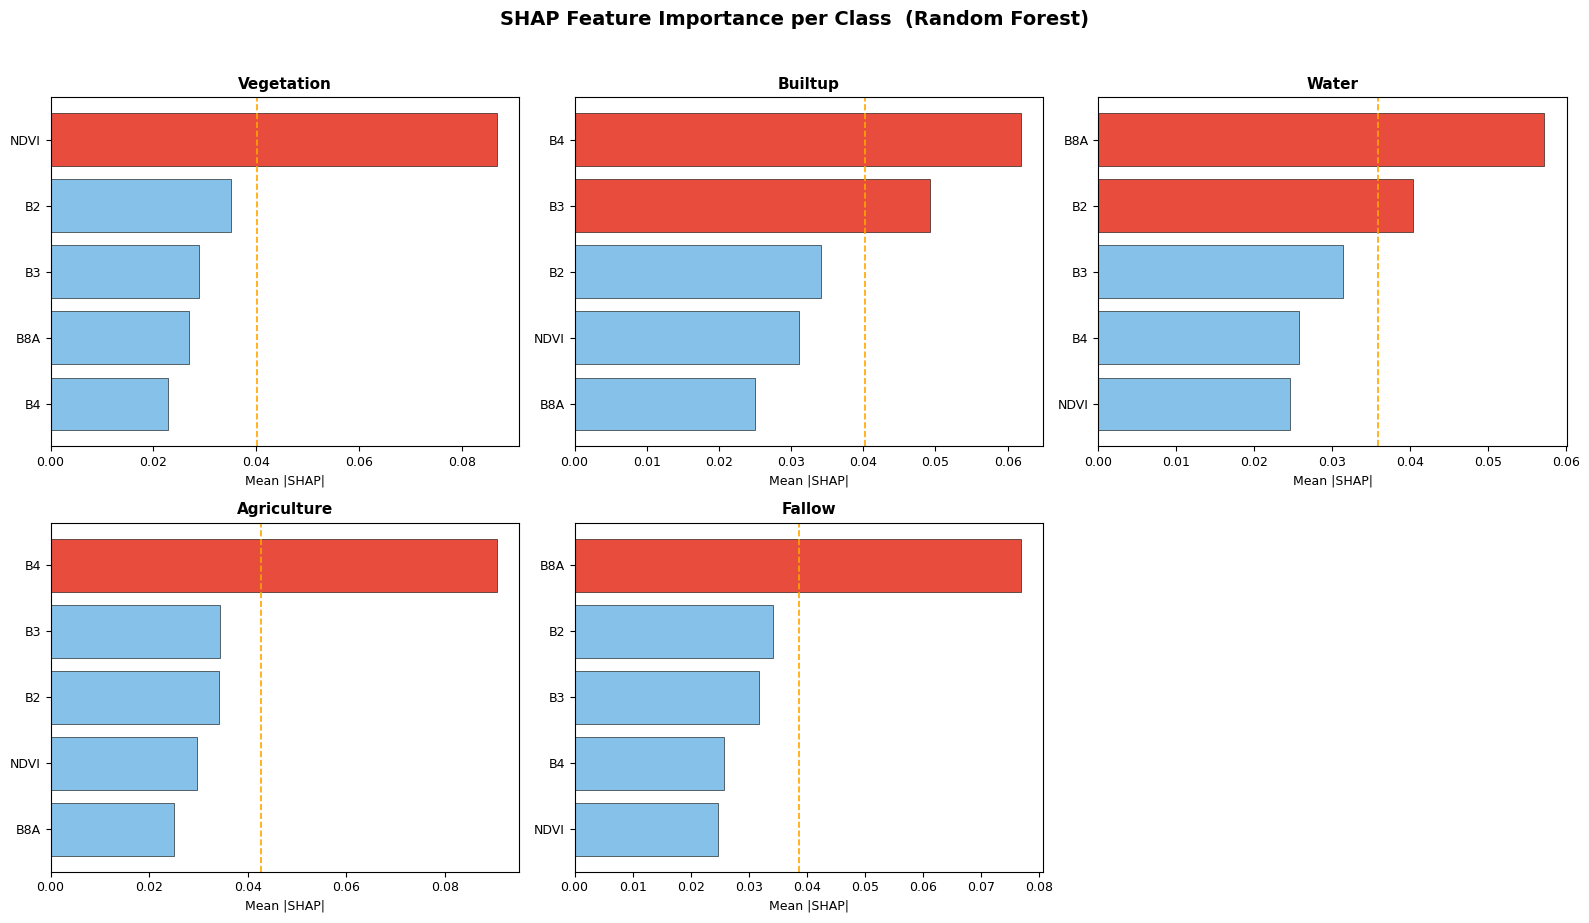

In [8]:
# ── Per-class SHAP bar chart (mean |SHAP| per feature, per class) ─
CLASS_NAMES_LIST = [CLASS_MAP[i] for i in sorted(CLASS_MAP)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, (ax, cls_name) in enumerate(zip(axes.flat, CLASS_NAMES_LIST)):
    importances = np.abs(shap_values_rf[i]).mean(axis=0)
    order = np.argsort(importances)
    colors = ['#E74C3C' if v > importances.mean() else '#85C1E9'
              for v in importances[order]]
    ax.barh([FEATURE_NAMES[j] for j in order], importances[order],
            color=colors, edgecolor='black', linewidth=0.4)
    ax.axvline(importances.mean(), color='orange', linestyle='--',
               linewidth=1.2, label='Mean')
    ax.set_title(cls_name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Mean |SHAP|', fontsize=9)
    ax.tick_params(labelsize=9)

axes.flat[-1].set_visible(False)
plt.suptitle('SHAP Feature Importance per Class  (Random Forest)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


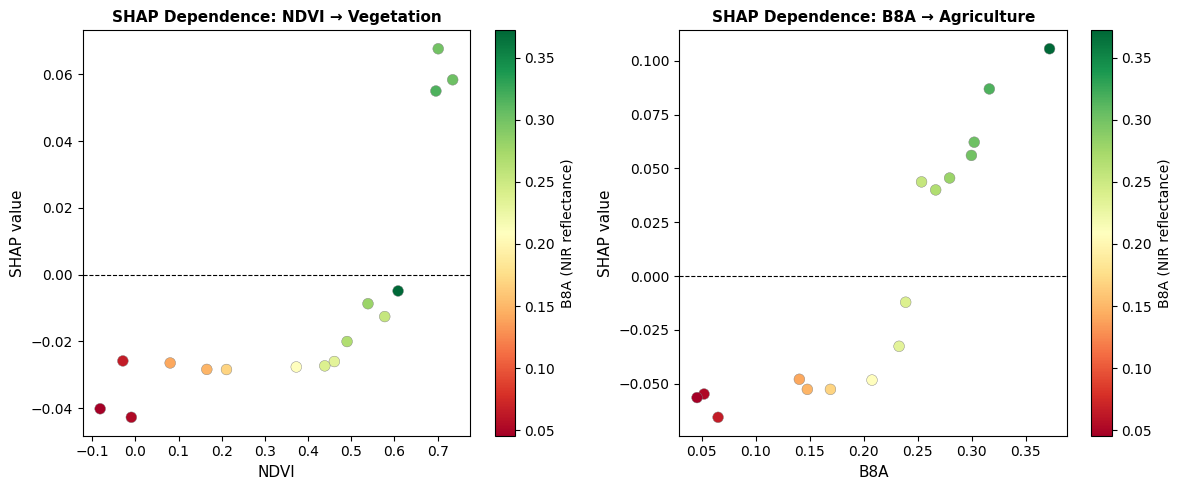

In [15]:
# ── SHAP dependence plot – NDVI for Vegetation class ──────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ndvi_idx = FEATURE_NAMES.index('NDVI')
b8a_idx  = FEATURE_NAMES.index('B8A')

if shap_values_rf.shape == (16, 8, 5):
    shap_values_rf_aligned = np.transpose(shap_values_rf, (2, 0, 1))
else:
    shap_values_rf_aligned = shap_values_rf

# Note: shap_values_rf_aligned has shape (5, 16, 8) -> shap_values_rf_aligned[cls_idx] has shape (16, 8)
for ax, (feat_idx, feat_name, cls_idx, cls_name) in zip(axes, [
    (ndvi_idx, 'NDVI', 0, 'Vegetation'),
    (b8a_idx,  'B8A',  3, 'Agriculture')]):

    sc = ax.scatter(X_test[:, feat_idx],
                    shap_values_rf_aligned[cls_idx][:, feat_idx],
                    c=X_test[:, b8a_idx],
                    cmap='RdYlGn', edgecolors='grey', linewidths=0.3, s=60)
    plt.colorbar(sc, ax=ax, label='B8A (NIR reflectance)')
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlabel(feat_name, fontsize=11)
    ax.set_ylabel('SHAP value', fontsize=11)
    ax.set_title(f'SHAP Dependence: {feat_name} → {cls_name}',
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 5 · SHAP for XGBoost


XGBoost SHAP shape: (16, 8, 5)


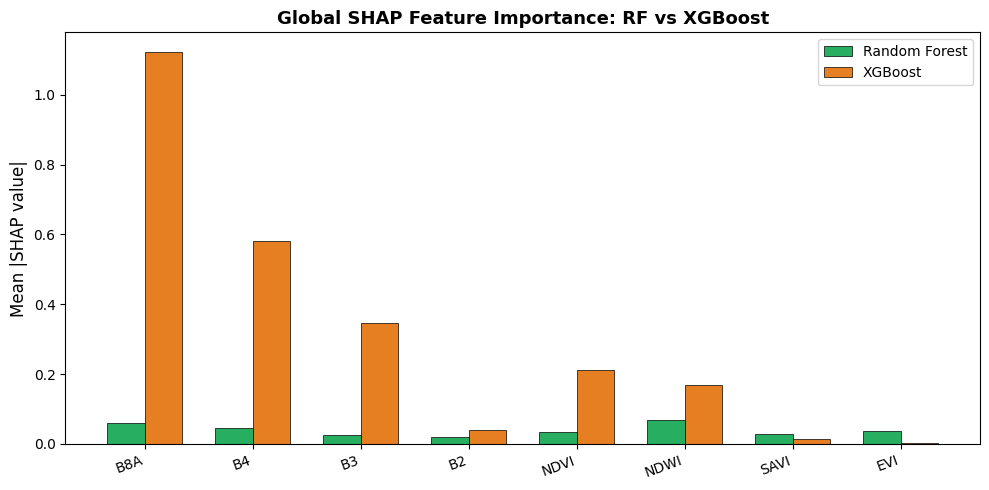

In [16]:
explainer_xgb = shap.TreeExplainer(best_xgb)

# XGBoost SHAP values for multiclass
shap_values_xgb = np.array(explainer_xgb.shap_values(X_test))
print(f"XGBoost SHAP shape: {shap_values_xgb.shape}")

# Align RF and XGBoost SHAP values shapes to (n_classes, n_samples, n_features)
if shap_values_rf.shape == (16, 8, 5):
    shap_values_rf_aligned = np.transpose(shap_values_rf, (2, 0, 1))
else:
    shap_values_rf_aligned = shap_values_rf

if shap_values_xgb.shape == (16, 8, 5):
    shap_values_xgb_aligned = np.transpose(shap_values_xgb, (2, 0, 1))
else:
    shap_values_xgb_aligned = shap_values_xgb

# Global mean |SHAP| comparison: RF vs XGBoost
shap_rf_global  = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_rf_aligned],  axis=0)
shap_xgb_global = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_xgb_aligned], axis=0)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(FEATURE_NAMES))
width = 0.35
ax.bar(x - width/2, shap_rf_global,  width, label='Random Forest', color='#27AE60',
       edgecolor='black', linewidth=0.5)
ax.bar(x + width/2, shap_xgb_global, width, label='XGBoost',       color='#E67E22',
       edgecolor='black', linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(FEATURE_NAMES, rotation=20, ha='right')
ax.set_ylabel('Mean |SHAP value|', fontsize=12)
ax.set_title('Global SHAP Feature Importance: RF vs XGBoost', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 6 · Comprehensive Feature Importance Comparison

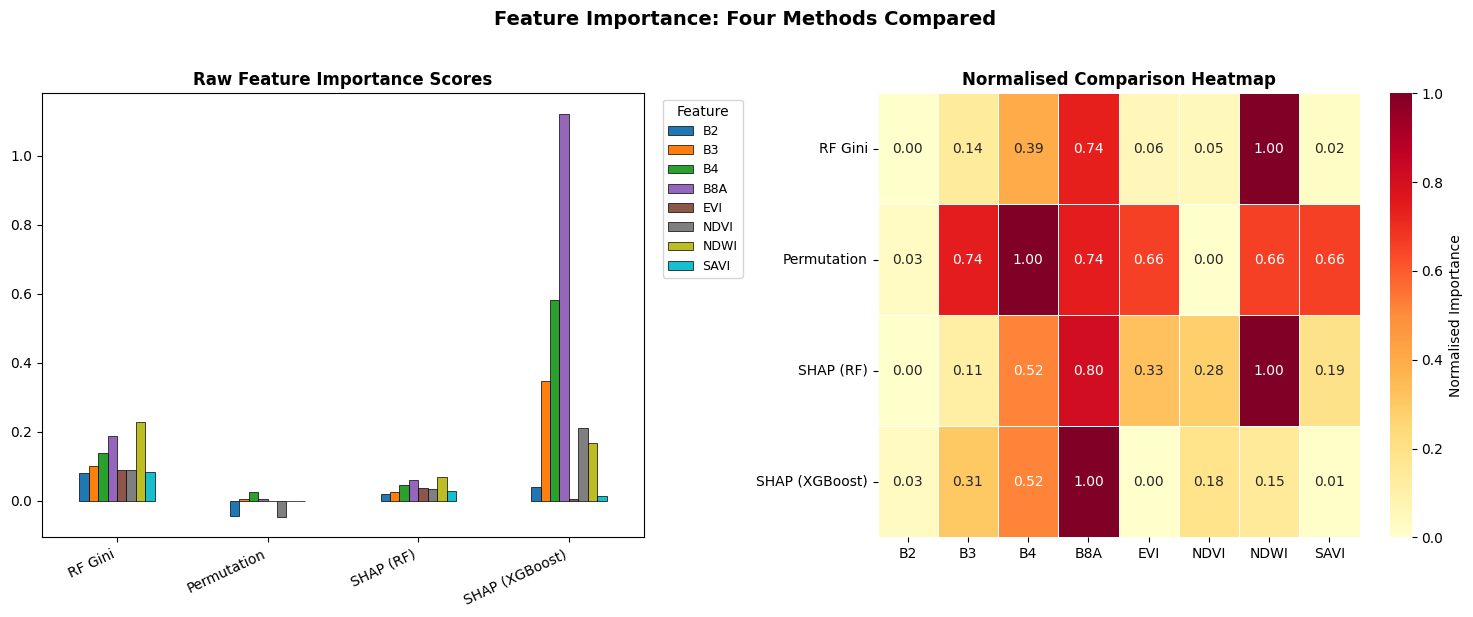


Ranking summary (by mean normalised importance):
B8A     0.820824
NDWI    0.700822
B4      0.607162
B3      0.325323
EVI     0.260184
SAVI    0.219020
NDVI    0.128267
B2      0.015373


In [17]:
# Compile all three methods into a single comparison table
methods = {
    'RF Gini'       : pd.Series(best_rf.feature_importances_, index=FEATURE_NAMES),
    'Permutation'   : perm_df.set_index('feature')['mean'],
    'SHAP (RF)'     : pd.Series(shap_rf_global, index=FEATURE_NAMES),
    'SHAP (XGBoost)': pd.Series(shap_xgb_global, index=FEATURE_NAMES),
}

compare_df = pd.DataFrame(methods).fillna(0)
# Normalise each method to [0, 1] for fair comparison
compare_norm = compare_df.apply(lambda col: (col - col.min()) / (col.max() - col.min()))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Raw values
compare_df.T.plot(kind='bar', ax=axes[0], colormap='tab10', edgecolor='black', linewidth=0.5)
axes[0].set_title('Raw Feature Importance Scores', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha='right')
axes[0].legend(title='Feature', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

# Normalised heatmap
sns.heatmap(compare_norm.T, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Normalised Importance'})
axes[1].set_title('Normalised Comparison Heatmap', fontsize=12, fontweight='bold')
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)

plt.suptitle('Feature Importance: Four Methods Compared', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nRanking summary (by mean normalised importance):")
print(compare_norm.mean(axis=1).sort_values(ascending=False).to_string())


SHAP Waterfall Plot – single prediction explanation



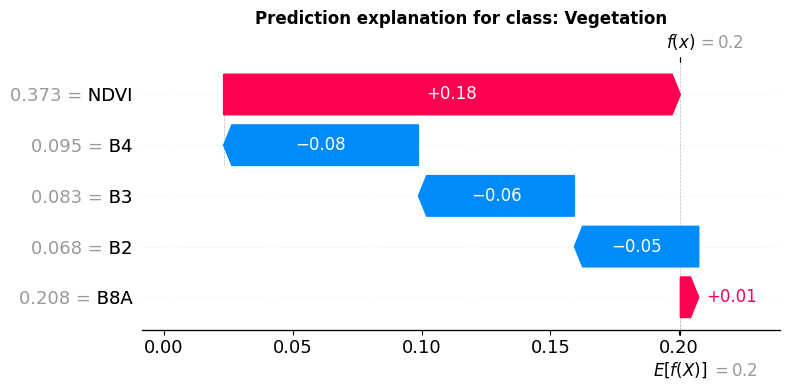

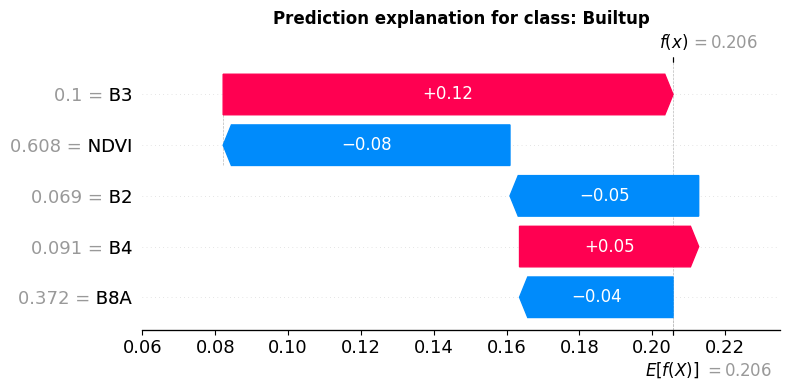

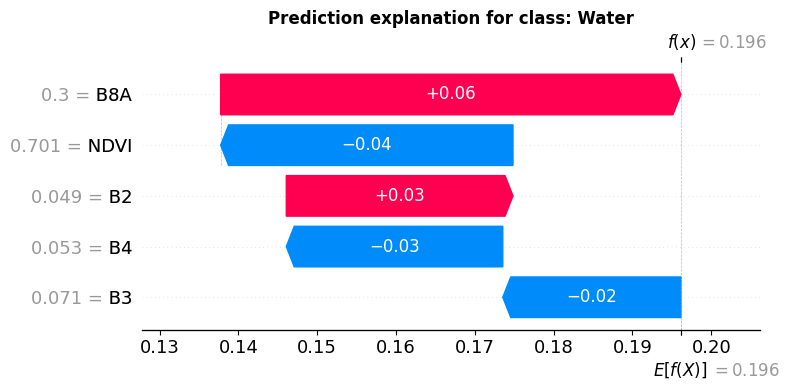

In [18]:
# SHAP waterfall plot for a single test sample (most informative per class)
print("SHAP Waterfall Plot – single prediction explanation\n")

for cls_idx, cls_name in enumerate(CLASS_NAMES_LIST[:3]):  # first 3 classes
    # Find the test sample with highest probability for this class
    sample_idx = np.argmax(shap_values_rf[cls_idx].sum(axis=1))

    shap_exp = shap.Explanation(
        values      = shap_values_rf[cls_idx][sample_idx],
        base_values = explainer_rf.expected_value[cls_idx],
        data        = X_test[sample_idx],
        feature_names = FEATURE_NAMES
    )
    shap.waterfall_plot(shap_exp, show=False)
    plt.title(f'Prediction explanation for class: {cls_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()


## Summary

| Method | Measures | Pros | Cons |
|--------|----------|------|------|
| **RF Gini** | Mean decrease in impurity | Fast, built-in | Biased toward high-cardinality features |
| **Permutation** | Accuracy drop on shuffled feature | Model-agnostic, unbiased | Slow on large datasets |
| **SHAP (Tree)** | Shapley contribution per sample | Consistent, per-class, local explanations | Computationally expensive for deep ensembles |

**Key findings from this dataset:**
- NDVI and B8A (NIR) are consistently the most important features across all methods
- NDWI is the most discriminating feature for the *Water* class
- Spectral indices add meaningful information beyond raw reflectance bands

**Practical advice:** Always compare at least two importance methods — if they agree, you can trust the ranking; if they disagree, investigate why.
